In [10]:
!pip install tensorflow pandas numpy matplotlib scikit-learn -q

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [11]:
df = pd.read_csv("Weather_Data.csv")

In [12]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3271 entries, 0 to 3270
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           3271 non-null   object 
 1   MinTemp        3271 non-null   float64
 2   MaxTemp        3271 non-null   float64
 3   Rainfall       3271 non-null   float64
 4   Evaporation    3271 non-null   float64
 5   Sunshine       3271 non-null   float64
 6   WindGustDir    3271 non-null   object 
 7   WindGustSpeed  3271 non-null   int64  
 8   WindDir9am     3271 non-null   object 
 9   WindDir3pm     3271 non-null   object 
 10  WindSpeed9am   3271 non-null   int64  
 11  WindSpeed3pm   3271 non-null   int64  
 12  Humidity9am    3271 non-null   int64  
 13  Humidity3pm    3271 non-null   int64  
 14  Pressure9am    3271 non-null   float64
 15  Pressure3pm    3271 non-null   float64
 16  Cloud9am       3271 non-null   int64  
 17  Cloud3pm       3271 non-null   

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000
mean,14.877102,23.005564,3.342158,5.175787,7.168970,41.476307,15.077041,19.294405,68.243962,54.698563,1018.334424,1016.003085,4.318557,4.176093,17.821461,21.543656
std,4.554710,4.483752,9.917746,2.757684,3.815966,10.806951,7.043825,7.453331,15.086127,16.279241,7.020090,7.019915,2.526923,2.411274,4.894316,4.297053
min,4.300000,11.700000,0.000000,0.000000,0.000000,17.000000,0.000000,0.000000,19.000000,10.000000,986.700000,989.800000,0.000000,0.000000,6.400000,10.200000
25%,11.000000,19.600000,0.000000,3.200000,4.250000,35.000000,11.000000,15.000000,58.000000,44.000000,1013.700000,1011.300000,2.000000,2.000000,13.800000,18.400000
50%,14.900000,22.800000,0.000000,4.800000,8.300000,41.000000,15.000000,19.000000,69.000000,56.000000,1018.600000,1016.300000,5.000000,4.000000,18.200000,21.300000
75%,18.800000,26.000000,1.400000,7.000000,10.200000,44.000000,20.000000,24.000000,80.000000,64.000000,1023.100000,1020.800000,7.000000,7.000000,21.700000,24.500000
max,27.600000,45.800000,119.400000,18.400000,13.600000,96.000000,54.000000,57.000000,100.000000,99.000000,1039.000000,1036.700000,9.000000,8.000000,36.500000,44.700000


In [13]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

df['MaxTemp'] = pd.to_numeric(df['MaxTemp'], errors='coerce')

df = df[['Date', 'MaxTemp']].dropna()

df = df.sort_values('Date').reset_index(drop=True)

df['MaxTemp'] = df['MaxTemp'].interpolate(method='linear')

df = df.dropna()

print("Preprocessed Dataset:")
display(df.head())

print("Total Records:", len(df))

Preprocessed Dataset:


,Date,MaxTemp
0,2008-02-01,22.4
1,2008-02-02,25.6
2,2008-02-03,24.5
3,2008-02-04,22.8
4,2008-02-05,25.7


Total Records: 3271


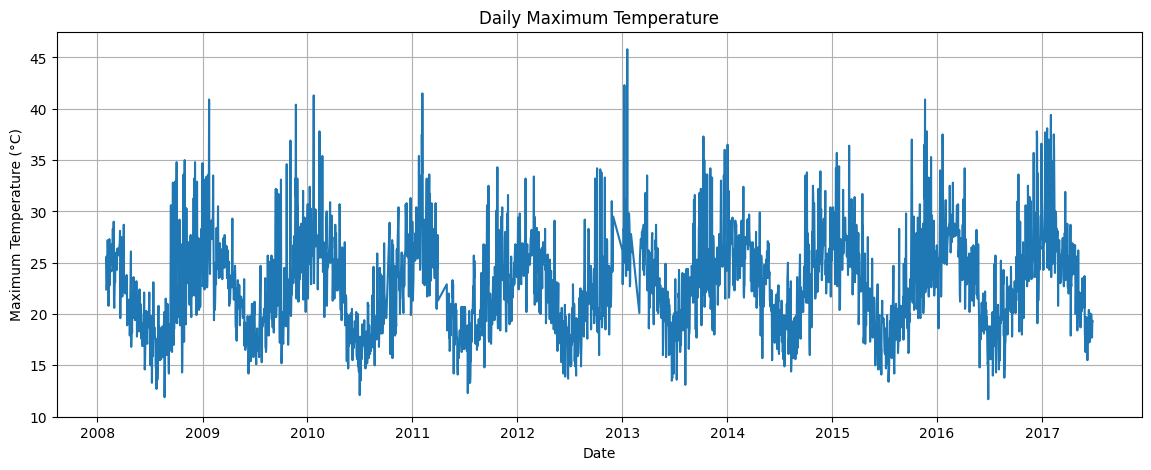

In [14]:
plt.figure(figsize=(14, 5))

plt.plot(df['Date'], df['MaxTemp'])

plt.title('Daily Maximum Temperature')
plt.xlabel('Date')
plt.ylabel('Maximum Temperature (°C)')

plt.grid(True)
plt.show()

In [15]:
values = df['MaxTemp'].values.reshape(-1, 1)

train_size = int(len(values) * 0.80)

train_data = values[:train_size]
test_data = values[train_size:]

scaler = MinMaxScaler(feature_range=(0, 1))

train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

print("Training Samples:", len(train_data))
print("Testing Samples:", len(test_data))

Training Samples: 2616
Testing Samples: 655


In [16]:
time_step = 30

def create_sequences(data, time_step):
    X, y = [], []

    for i in range(time_step, len(data)):
        X.append(data[i-time_step:i, 0])
        y.append(data[i, 0])

    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, time_step)
X_test, y_test = create_sequences(test_scaled, time_step)

X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)
print("X_test Shape:", X_test.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (2586, 30, 1)
y_train Shape: (2586,)
X_test Shape: (625, 30, 1)
y_test Shape: (625,)


In [17]:
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(time_step, 1)),
    Dropout(0.2),

    LSTM(32, return_sequences=False),
    Dropout(0.2),

    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
73/73 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - loss: 0.0177 - mae: 0.0988 - val_loss: 0.0076 - val_mae: 0.0673
Epoch 2/50
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - loss: 0.0105 - mae: 0.0765 - val_loss: 0.0071 - val_mae: 0.0636
Epoch 3/50
73/73 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - loss: 0.0102 - mae: 0.0755 - val_loss: 0.0076 - val_mae: 0.0660
Epoch 4/50
73/73 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - loss: 0.0102 - mae: 0.0752 - val_loss: 0.0070 - val_mae: 0.0632
Epoch 5/50
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0102 - mae: 0.0745 - val_loss: 0.0076 - val_mae: 0.0658
Epoch 6/50
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0099 - mae: 0.0741 - val_loss: 0.0072 - val_mae: 0.0632
Epoch 7/50
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.0097 - mae: 0.0730 - val_loss: 0.0070 - val_mae: 0.0627
Epoch 8/50
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.0099 - mae: 0.0744 - val_loss: 0.0074 - val_mae: 0.0649
Epoch 9/50
73/73 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 0.0

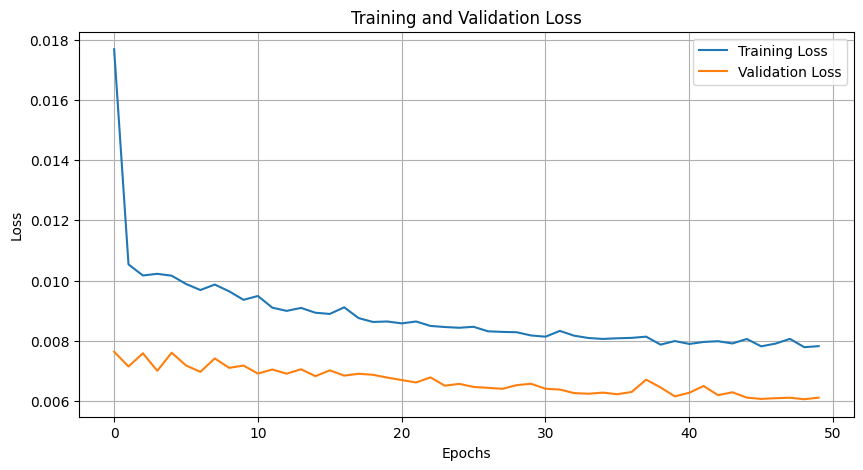

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.show()

In [20]:
predictions_scaled = model.predict(X_test)

predictions = scaler.inverse_transform(predictions_scaled)

actual = scaler.inverse_transform(y_test.reshape(-1, 1))

print("Predictions generated successfully!")
print("Number of Predictions:", len(predictions))

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step
Predictions generated successfully!
Number of Predictions: 625


In [21]:
mse = mean_squared_error(actual, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(actual, predictions)
r2 = r2_score(actual, predictions)

print("Model Evaluation Results")
print("------------------------")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} °C")
print(f"Mean Absolute Error (MAE): {mae:.4f} °C")
print(f"R² Score: {r2:.4f}")

Model Evaluation Results
------------------------
Mean Squared Error (MSE): 9.6611
Root Mean Squared Error (RMSE): 3.1082 °C
Mean Absolute Error (MAE): 2.1801 °C
R² Score: 0.5386


In [22]:
test_dates = df['Date'].iloc[train_size + time_step:].reset_index(drop=True)

results = pd.DataFrame({
    'Date': test_dates,
    'Actual_MaxTemp': actual.flatten(),
    'Predicted_MaxTemp': predictions.flatten()
})

display(results.head(10))

,Date,Actual_MaxTemp,Predicted_MaxTemp
0,2015-10-01,22.9,20.932755
1,2015-10-02,23.0,21.829288
2,2015-10-03,27.5,21.947872
3,2015-10-04,33.8,23.924932
4,2015-10-05,37.0,26.247406
5,2015-10-06,32.3,27.598267
6,2015-10-07,21.5,26.889284
7,2015-10-08,21.1,24.044653
8,2015-10-09,22.7,24.115101
9,2015-10-10,24.3,24.484999


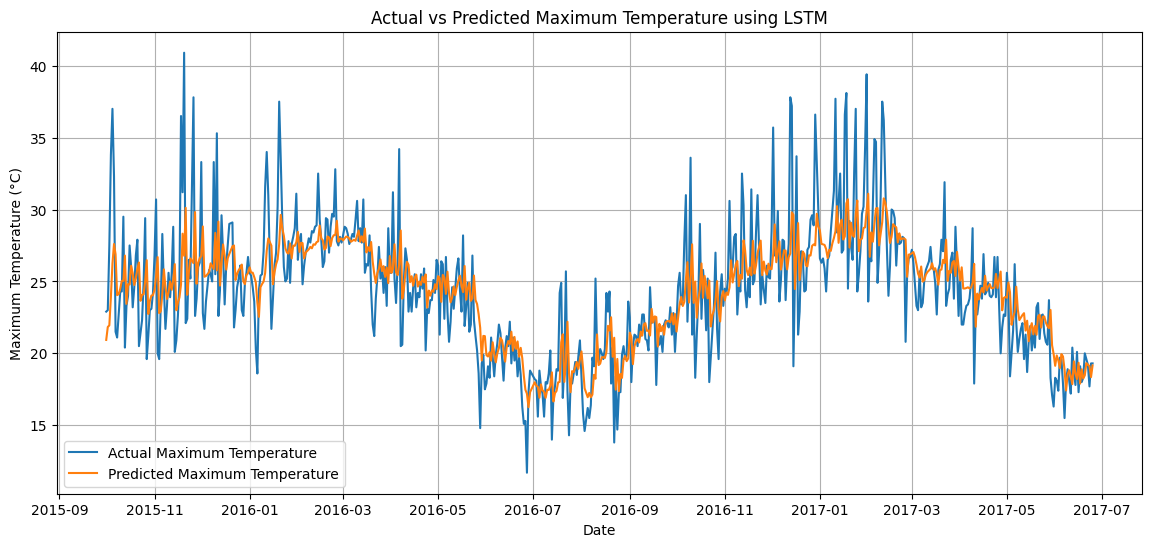

In [23]:
plt.figure(figsize=(14, 6))

plt.plot(
    results['Date'],
    results['Actual_MaxTemp'],
    label='Actual Maximum Temperature'
)

plt.plot(
    results['Date'],
    results['Predicted_MaxTemp'],
    label='Predicted Maximum Temperature'
)

plt.title('Actual vs Predicted Maximum Temperature using LSTM')
plt.xlabel('Date')
plt.ylabel('Maximum Temperature (°C)')

plt.legend()
plt.grid(True)
plt.show()